In [3]:

#importing relevant libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


In [14]:
#creating the solow model
def solow_path(alpha, s, delta, n, g, k0, T=100, dt=0.25, t0=0.0):
    phi = delta + n + g
    t = np.arange(0, T + dt, dt)
    sol = solve_ivp(lambda t, k: s*k**alpha - phi*k, (0, T), [k0],
                    t_eval=t, rtol=1e-10, atol=1e-12)
    k_an = (s/phi + (k0**(1-alpha) - s/phi)*np.exp(-(1-alpha)*phi*t))**(1/(1-alpha))
    return pd.DataFrame({"t": t + t0, "k_numeric": sol.y[0], "k_analytic": k_an})

In [ ]:
#calculating parametres
def steady_state_table(alpha,s,delta,n,g):
    phi = delta + n + g
    lam = (1-alpha)*phi
    return pd.Series({"k_star":(s/phi)**(1/(1-alpha)),
               "y_star":(s/phi)**(alpha/(1-alpha)),
               "k_golden": (alpha/phi)**(1/(1-alpha)),
               "s_golden":alpha,"lambda":lam,
               "half_life":np.log(2)/lam})
    


In [24]:
#parametres(text book values)
#case 1 : s=0.20
#case 2: s=0.50
p=dict(alpha=1/3,delta=0.05,n=0.02,g=0.02,)
s_old, s_new, t_shock = 0.20, 0.50, 20

#start with old state, move to t=20
k_star_old = steady_state_table(s=s_old,**p)["k_star"]
before = solow_path(s = s_old,k0 = k_star_old, T=t_shock,**p)
after = solow_path(s=s_new,k0=before["k_analytic"].iloc[-1],T=80,t0=t_shock,**p)
df = pd.concat([before,after.iloc[1:]],ignore_index=True)

s_t = np.where(df["t"]<t_shock,s_old,s_new)
df["y"]=df["k_analytic"]**p["alpha"]
df["c"]=(1-s_t)*df["y"]
df["Y_per_worker"]=np.exp(p["g"]*df["t"])*df["y"] #assumes A(0)=1
df["abs_error"]=(df["k_numeric"]-df["k_analytic"]).abs()

print(df.abs_error.max())
print(steady_state_table(s=s_new,**p))


4.405027453913135e-09
k_star       13.094570
y_star        2.357023
k_golden      7.127781
s_golden      0.333333
lambda        0.060000
half_life    11.552453
dtype: float64


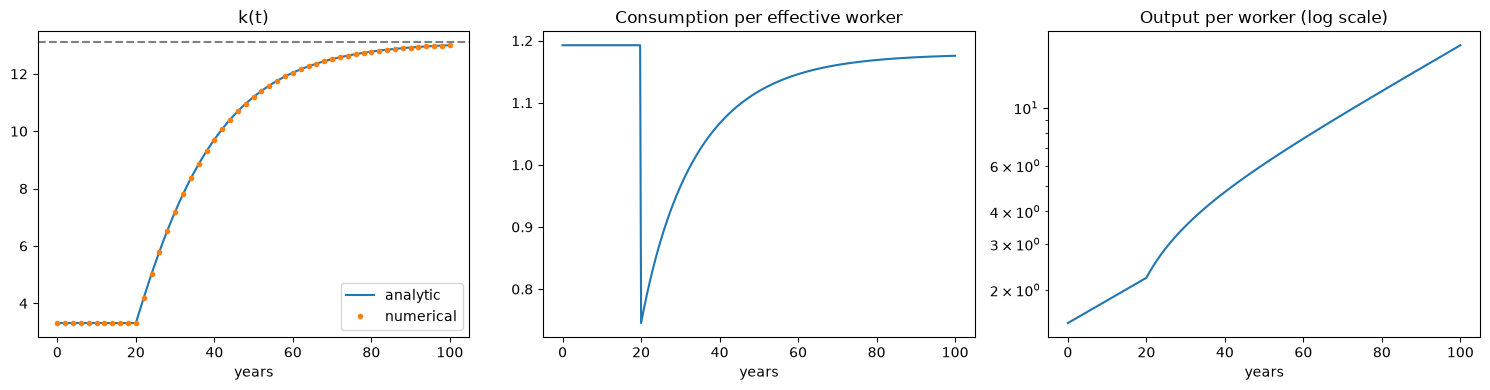

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(df.t, df.k_analytic, label="analytic")
ax[0].plot(df.t[::8], df.k_numeric[::8], "o", ms=3, label="numerical")
ax[0].axhline(steady_state_table(s=s_new, **p)["k_star"], ls="--", c="grey")
ax[0].set(title="k(t)", xlabel="years"); ax[0].legend()
ax[1].plot(df.t, df.c); ax[1].set(title="Consumption per effective worker", xlabel="years")
ax[2].semilogy(df.t, df.Y_per_worker); ax[2].set(title="Output per worker (log scale)", xlabel="years")
plt.tight_layout(); plt.show()